In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import libpysal as lp
from esda import Moran, Moran_Local
from splot.esda import plot_moran, plot_local_autocorrelation
import geopandas as gpd
from shapely.geometry import Point
import os
import pyproj
print("pyproj version:", pyproj.__version__)
print("PROJ_LIB env:", os.environ.get('PROJ_LIB', 'Not set'))
print("Data dirs:", pyproj.datadir.get_data_dir())
# ==================== 1. 解决中文字体问题 ====================
plt.rcParams['font.family'] = ['Times new Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)
c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pyproj version: 3.7.2
PROJ_LIB env: Not set
Data dirs: c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\proj_dir\share\proj


In [2]:
import pyproj
pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
print(pyproj.datadir.get_data_dir())  # 应该显示新路径
crs = pyproj.CRS("EPSG:4326")
print(crs)

C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj
EPSG:4326


In [3]:
# 加载数据
df_SHF = pd.read_excel('../output/interpolated_to_SHF.xlsx')
df_GEO = pd.read_excel('../output/grid_0.2deg.xlsx')

列检测: lon=Lon, lat=Lat, shf=SHF__mW_m2_
Global Moran's I: 0.2715, p-value (randomization): 0.0010


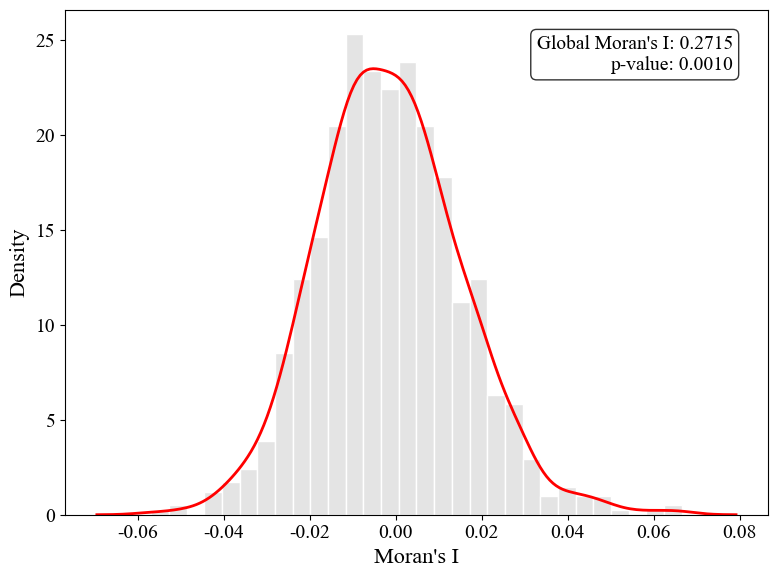

In [4]:
# ==================== Spatial Autocorrelation Analysis ====================
# 自动检测经纬度列（兼容 Lon/Lat 与 Longitude/Latitude 两种命名）
_lon_col = next((cc for cc in ['Lon', 'Longitude', 'lon', 'longitude'] if cc in df_SHF.columns), None)
_lat_col = next((cc for cc in ['Lat', 'Latitude', 'lat', 'latitude'] if cc in df_SHF.columns), None)
if _lon_col is not None and _lat_col is not None:
    import geopandas as gpd
    from shapely.geometry import Point
    import libpysal as lp
    from esda.moran import Moran
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np

    # Set default font (optional, but keep for compatibility)
    plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'WenQuanYi Zen Hei']
    plt.rcParams['axes.unicode_minus'] = False

    # Create GeoDataFrame
    # SHF 目标列（优先精确列名，其次含 'shf' 的列）
    _shf_col = next((cc for cc in ['SHF__mW_m2_', 'SHF_resampled', 'SHF'] if cc in df_SHF.columns), None)
    if _shf_col is None:
        _shf_col = next((cc for cc in df_SHF.columns if 'shf' in cc.lower()), None)
    print(f"列检测: lon={_lon_col}, lat={_lat_col}, shf={_shf_col}")

    gdf = gpd.GeoDataFrame(df_SHF, geometry=[Point(xy) for xy in zip(df_SHF[_lon_col], df_SHF[_lat_col])], crs='EPSG:4326')
    
    # Build spatial weights matrix
    coords = list(zip(gdf.geometry.x, gdf.geometry.y))
    w = lp.weights.KNN(coords, k=8)
    w.transform = 'R'

    # Global Moran's I (with randomization test)
    y = gdf[_shf_col].values
    moran = Moran(y, w, permutations=999)
    print(f"Global Moran's I: {moran.I:.4f}, p-value (randomization): {moran.p_sim:.4f}")

    # Increase global font size
    plt.rcParams.update({'font.size': 14})

    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Histogram (light gray, only bars)
    sns.histplot(moran.sim, bins=30, stat='density',
                 color='lightgray', edgecolor='white', alpha=0.6, ax=ax)
    
    # Red KDE curve
    sns.kdeplot(moran.sim, color='red', linewidth=2, ax=ax)
    
    # Labels in English
    ax.set_xlabel("Moran's I", fontsize=16)
    ax.set_ylabel("Density", fontsize=16)
    
    # Text box in English, placed at upper right
    textstr = f"Global Moran's I: {moran.I:.4f}\np-value: {moran.p_sim:.4f}"
    ax.text(0.95, 0.95, textstr, transform=ax.transAxes, fontsize=14,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    plt.tight_layout()
    plt.savefig('../output/fig/moran_distribution1.png', dpi=900, bbox_inches='tight')
    plt.show()

else:
    print("df_SHF lacks Lon/Lat columns, spatial autocorrelation analysis cannot be performed.")

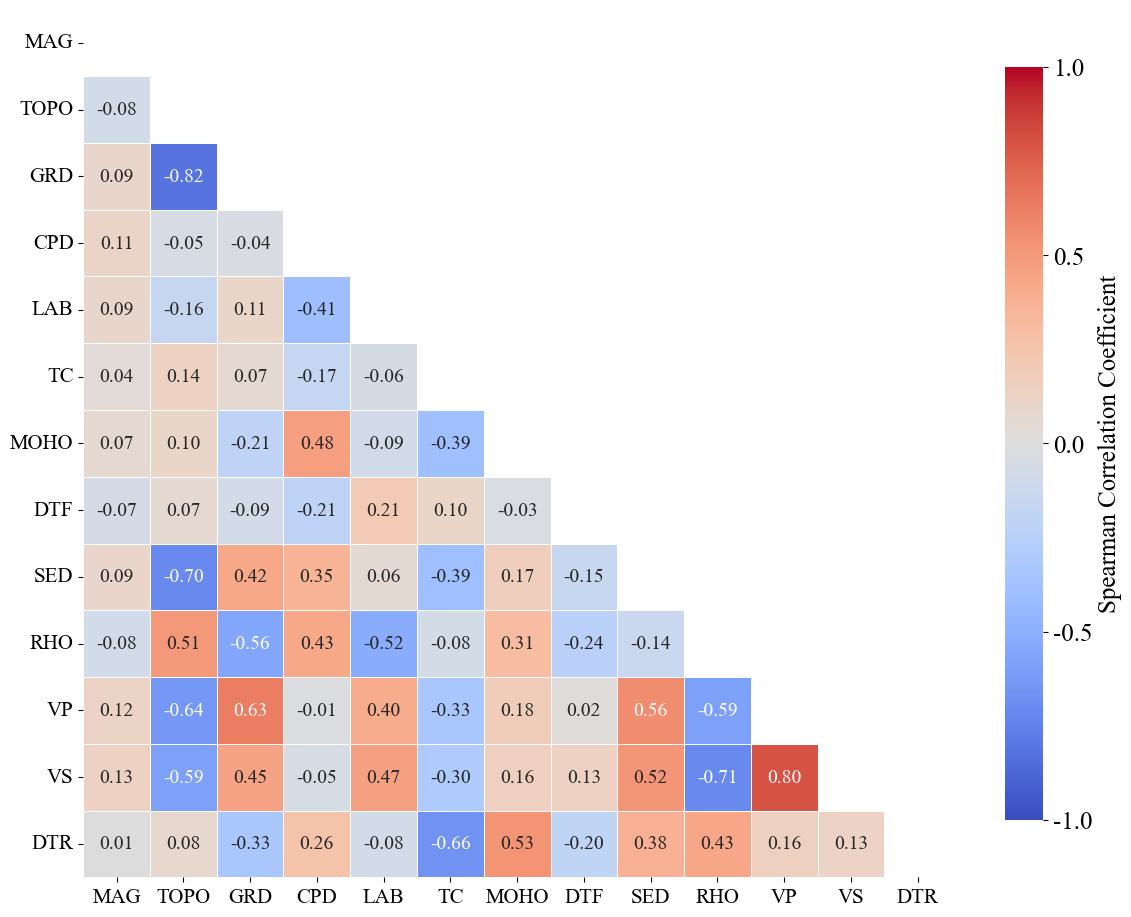

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   # 确保已导入 seaborn

# ==================== Geological Dataset Correlation Analysis ====================
# Specified geological feature columns
GEO_COLS = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU',
    'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF',
    'sedthk-m', 'ro6', 'vp7', 'vs8',
    'DTR'
]

# Merged column names for analysis
selected_cols = ['MAG', 'TOPO', 'GRD', 'CPD', 'LAB', 'TC', 'MOHO', 'DTF', 'SED', 'RHO', 'VP', 'VS', 'DTR']

# Mapping from original GEO_COLS to new column names
geo_rename_dict = dict(zip(GEO_COLS, ['MAG', 'TOPO', 'GRD', 'CPD', 'LAB', 'TC', 'MOHO', 'DTF', 'SED', 'RHO', 'VP', 'VS', 'DTR']))

df_GEO.rename(columns=geo_rename_dict, inplace=True)

# Check if these columns exist in df_GEO
missing_cols = [col for col in selected_cols if col not in df_GEO.columns]
if missing_cols:
    print(f"Warning: The following columns are missing and will be skipped: {missing_cols}")
    selected_cols = [col for col in selected_cols if col in df_GEO.columns]

if len(selected_cols) > 1:
    # Extract subset and compute Spearman correlation
    df_subset = df_GEO[selected_cols]
    corr_matrix = df_subset.corr(method='spearman')
    
    # Create mask for upper triangle (including diagonal)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    plt.figure(figsize=(12, 10))
    
    # ---------- 修改处：将列名 'DEM' 显示为 'TOPO' ----------
    labels = ['TOPO' if col == 'DEM' else col for col in selected_cols]   # 替换显示标签
    
    # Draw heatmap with fixed color range [-1, 1], enlarged fonts
    ax = sns.heatmap(corr_matrix, 
                     mask=mask, 
                     annot=True, 
                     fmt='.2f', 
                     cmap='coolwarm', 
                     vmin=-1, vmax=1,
                     square=True, 
                     linewidths=0.5,
                     annot_kws={'size': 14},
                     cbar_kws={'shrink': 0.8, 'ticks': [-1, -0.5, 0, 0.5, 1]},
                     xticklabels=labels,   # 使用修改后的标签
                     yticklabels=labels)   # 使用修改后的标签
    
    # Set tick label font sizes for x and y axes
    ax.tick_params(axis='x', labelsize=15, rotation=0)
    ax.tick_params(axis='y', labelsize=15, rotation=0)
    
    # Adjust colorbar tick labels and add label in English
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label('Spearman Correlation Coefficient', fontsize=18)
    
    plt.tight_layout()
    plt.savefig('../output/fig/preprocess/geological_correlation_heatmap.png', dpi=2000, bbox_inches='tight')
    plt.show()
else:
    print("Less than two selected columns, correlation cannot be computed")

SHF color range: [29.70, 100.00] mW/m²
Successfully built polygon from contour lines, area = 75.2983 square degrees
[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器
Terrain loaded via pygmt earth_relief: (811, 550), extent Lon [112.18, 123.62], Lat [22.82, 39.69]
Display extent based on observation points: Longitude [113.18, 122.62], Latitude [23.32, 39.19]
Expanded display extent: Longitude [112.18, 123.62], Latitude [22.82, 39.69]
TB boundary plotted successfully (black solid, clipped)
TLF boundary plotted successfully (red solid, clipped)
轮廓内观测点数: 561 / 703
轮廓内地表热流均值: 66.75 mW/m²


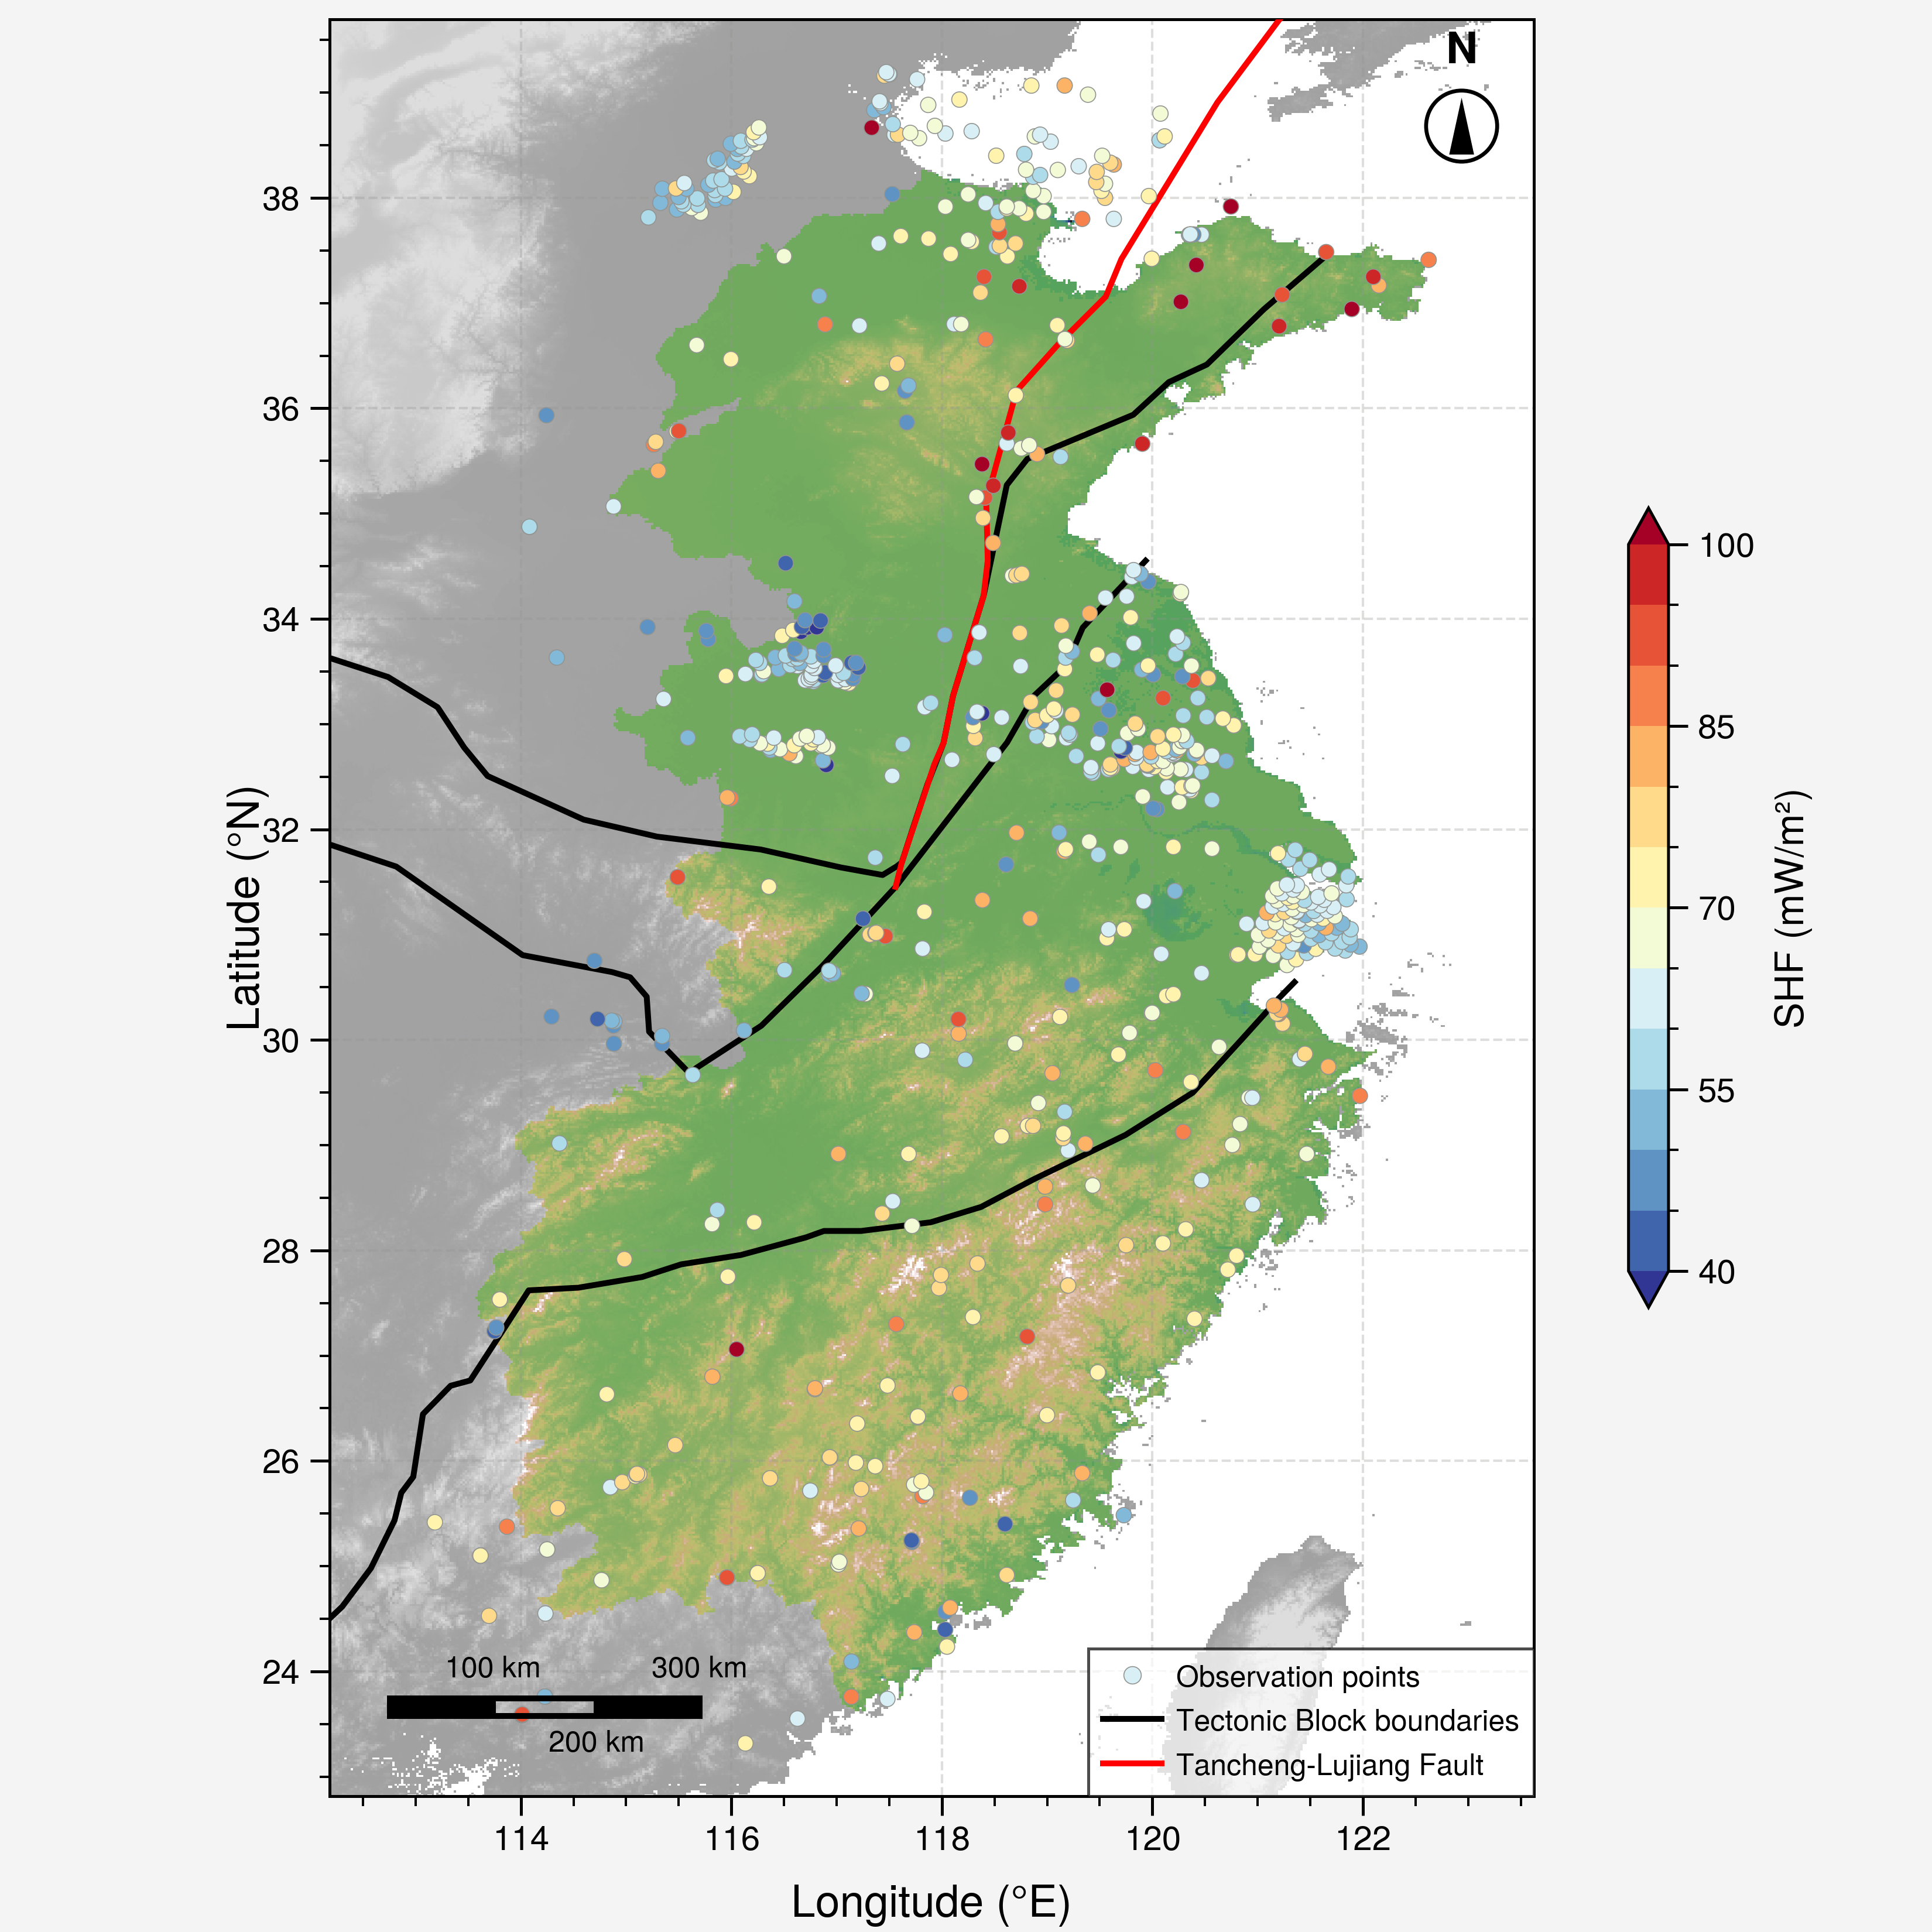

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import os
import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from matplotlib.lines import Line2D
from matplotlib.path import Path
import cartopy.crs as ccrs
from cartopy.mpl import path as cpath
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm
import ultraplot as pplt
import scienceplots

# ==================== JGR:SE Journal Style ====================
plt.style.use(['science', 'no-latex', 'ieee'])
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
pplt.rc['figure.dpi'] = 300
pplt.rc['font.size'] = 8
pplt.rc['axes.labelsize'] = 9
pplt.rc['legend.fontsize'] = 7
pplt.rc['xtick.labelsize'] = 7
pplt.rc['ytick.labelsize'] = 7
pplt.rc['subplots.tight'] = False

from shapely.geometry import Polygon, MultiPolygon, LineString, MultiLineString, Point
from shapely.ops import unary_union, polygonize

# ==================== Helper Functions ====================
def add_scale_bar_and_north_arrow(ax, segment_km=100, num_segments=4):
    """
    Scale bar and north arrow for PlateCarree projection.
    - Scale bar at lower-left (axes coords (0.03, 0.05)), segment length computed based on latitude.
    - North arrow at upper-right (axes coords (0.94, 0.94)), pointing to true north.
    """
    # ---------- Scale bar (bottom-right) ----------
    axes_coords = (0.05, 0.05)
    data_coords = ax.transData.inverted().transform(ax.transAxes.transform(axes_coords))
    x_start, y_base = data_coords
    lat = y_base
    cos_lat = max(np.cos(np.radians(lat)), 0.1)

    segment_length_deg = segment_km / (111.32 * cos_lat)

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    height = ylim[1] - ylim[0]
    bar_height = 0.010 * height

    for i in range(num_segments):
        x_left = x_start + i * segment_length_deg
        if x_left > xlim[1] + segment_length_deg * 2:
            break
        facecolor = 'black' if i % 2 == 0 else 'none'
        rect = plt.Rectangle(
            (x_left, y_base - bar_height / 2),
            segment_length_deg, bar_height,
            edgecolor='black', facecolor=facecolor,
            linewidth=1.2, clip_on=False, zorder=100
        )
        ax.add_patch(rect)

        cumulative_km = (i + 1) * segment_km
        if i % 2 == 0:
            text_y = y_base + bar_height / 2 + 0.008 * height
            va = 'bottom'
        else:
            text_y = y_base - bar_height / 2 - 0.008 * height
            va = 'top'
        ax.text(x_left + segment_length_deg, text_y,
                f'{cumulative_km} km', ha='center', va=va,
                fontsize=6, color='black', clip_on=False, zorder=100)

    # ---------- North arrow ----------
    north_axes = (0.94, 0.94)
    north_data = ax.transData.inverted().transform(ax.transAxes.transform(north_axes))
    x0, y0 = north_data
    radius = 0.02 * height
    arrow_length = 0.8 * radius

    circle = mpatches.Circle((x0, y0), radius, facecolor='white', edgecolor='black',
                             linewidth=0.8, zorder=100, clip_on=False)
    ax.add_patch(circle)

    arrow_top = y0 + arrow_length
    arrow_bottom = y0 - arrow_length
    triangle = mpatches.Polygon(
        [(x0, arrow_top), (x0 - 0.35 * radius, arrow_bottom), (x0 + 0.35 * radius, arrow_bottom)],
        facecolor='black', edgecolor='none', zorder=101, clip_on=False
    )
    ax.add_patch(triangle)

    ax.text(x0, y0 + radius + 0.01 * height, 'N',
            ha='center', va='bottom', fontsize=9, fontweight='bold',
            color='black', clip_on=False, zorder=100)

def get_xy(coords):
    xs = [c[0] for c in coords]
    ys = [c[1] for c in coords]
    return xs, ys

def plot_boundary_on_ax(ax, gdf, color='black', linewidth=1.5, linestyle='-', transform=None):
    """Draw boundary of GeoDataFrame with given linestyle."""
    if transform is None:
        transform = ax.transData
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type in ['Polygon', 'MultiPolygon']:
            geom = geom.boundary
        if geom.geom_type == 'LineString':
            try:
                xs, ys = get_xy(geom.coords)
                ax.plot(xs, ys, color=color, linewidth=linewidth, linestyle=linestyle, transform=transform)
            except Exception:
                continue
        elif geom.geom_type == 'MultiLineString':
            for line in geom.geoms:
                try:
                    xs, ys = get_xy(line.coords)
                    ax.plot(xs, ys, color=color, linewidth=linewidth, linestyle=linestyle, transform=transform)
                except Exception:
                    continue
        elif geom.geom_type in ['Point', 'MultiPoint']:
            continue
        else:
            try:
                boundary = geom.boundary
                if not boundary.is_empty:
                    if boundary.geom_type == 'LineString':
                        xs, ys = get_xy(boundary.coords)
                        ax.plot(xs, ys, color=color, linewidth=linewidth, linestyle=linestyle, transform=transform)
                    elif boundary.geom_type == 'MultiLineString':
                        for line in boundary.geoms:
                            xs, ys = get_xy(line.coords)
                            ax.plot(xs, ys, color=color, linewidth=linewidth, linestyle=linestyle, transform=transform)
            except Exception:
                continue

def plot_clipped_boundary(ax, gdf_boundary, clip_polygon, color='black', linewidth=1.2, linestyle='-', transform=None):
    """Plot clipped boundary lines."""
    if transform is None:
        transform = ax.transData
    if isinstance(clip_polygon, MultiPolygon):
        clip_polygon = unary_union(clip_polygon)
    for geom in gdf_boundary.geometry:
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type in ['Polygon', 'MultiPolygon']:
            geom = geom.boundary
        if geom.geom_type == 'LineString':
            lines = [geom]
        elif geom.geom_type == 'MultiLineString':
            lines = list(geom.geoms)
        else:
            continue
        for line in lines:
            clipped = line.intersection(clip_polygon)
            if clipped.is_empty:
                continue
            if clipped.geom_type == 'LineString':
                x_line, y_line = zip(*clipped.coords)
                ax.plot(x_line, y_line, color='white', linewidth=linewidth + 2.5, linestyle='-',
                        transform=transform, zorder=5, solid_capstyle='round')
                ax.plot(x_line, y_line, color=color, linewidth=linewidth, linestyle=linestyle,
                        transform=transform, zorder=6)
            elif clipped.geom_type == 'MultiLineString':
                for part in clipped.geoms:
                    if part.geom_type == 'LineString':
                        x_line, y_line = zip(*part.coords)
                        ax.plot(x_line, y_line, color='white', linewidth=linewidth + 2.5, linestyle='-',
                                transform=transform, zorder=5, solid_capstyle='round')
                        ax.plot(x_line, y_line, color=color, linewidth=linewidth, linestyle=linestyle,
                                transform=transform, zorder=6)


def plot_boundary(ax, gdf, color='red', linewidth=1.5, linestyle='-', transform=None):
    """Plot full boundary without clipping (无白色描边, 由坐标轴自然裁剪)."""
    if transform is None:
        transform = ax.transData
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type in ['Polygon', 'MultiPolygon']:
            geom = geom.boundary
        if geom.geom_type == 'LineString':
            x_line, y_line = zip(*geom.coords)
            ax.plot(x_line, y_line, color=color, linewidth=linewidth, linestyle=linestyle,
                    transform=transform, zorder=6)
        elif geom.geom_type == 'MultiLineString':
            for line in geom.geoms:
                x_line, y_line = zip(*line.coords)
                ax.plot(x_line, y_line, color=color, linewidth=linewidth, linestyle=linestyle,
                        transform=transform, zorder=6)

# ==================== Read SHF Data ====================
SHF_FILE = '../output/interpolated_to_SHF.xlsx'
try:
    df_SHF = pd.read_excel(SHF_FILE)
    lon_col = 'Lon'
    lat_col = 'Lat'
    shf_col = 'SHF__mW/m2_'
    if not all(col in df_SHF.columns for col in [lon_col, lat_col, shf_col]):
        # 优先匹配列名含 'shf' 的列；'Thermal Conductivity （mW/K/m/）' 含 'mw'，会误匹配，不能按 mw 选
        _lon_c = [col for col in df_SHF.columns if 'lon' in col.lower()]
        _lat_c = [col for col in df_SHF.columns if 'lat' in col.lower()]
        _shf_c = [col for col in df_SHF.columns if 'shf' in col.lower()]
        if not _shf_c:
            _shf_c = [col for col in df_SHF.columns if 'mw' in col.lower()]
        if _lon_c: lon_col = _lon_c[0]
        if _lat_c: lat_col = _lat_c[0]
        if _shf_c: shf_col = _shf_c[0]
        if not all(col in df_SHF.columns for col in [lon_col, lat_col, shf_col]):
            raise KeyError(f"Missing necessary columns in data, check file: {SHF_FILE}")
    lon = df_SHF[lon_col].values
    lat = df_SHF[lat_col].values
    shf = df_SHF[shf_col].values
    vmin = shf.min()
    vmax = 100.0
    print(f"SHF color range: [{vmin:.2f}, {vmax:.2f}] mW/m²")
except Exception as e:
    raise RuntimeError(f"Cannot read SHF data file {SHF_FILE}: {e}")

# ==================== Build Clipping Polygon from Contour Lines ====================
shapefile_path = '../data/eastChinaLine.shp'
try:
    gdf_lines = gpd.read_file(shapefile_path)
    if gdf_lines.crs is not None and gdf_lines.crs != 'EPSG:4326':
        gdf_lines = gdf_lines.to_crs('EPSG:4326')
    merged_lines = unary_union(gdf_lines.geometry)
    polygons = list(polygonize(merged_lines))
    if len(polygons) == 0:
        raise ValueError("Contour lines cannot form a closed polygon, check data.")
    contour_polygon = max(polygons, key=lambda p: p.area)
    print(f"Successfully built polygon from contour lines, area = {contour_polygon.area:.4f} square degrees")
except Exception as e:
    raise RuntimeError(f"Cannot build clipping polygon from contour file: {e}")

# ==================== 地形高程底图（pygmt SRTM15+，色盲友好渲染） ====================
# 取消 DEM.xls + 克里金插值 + 裁剪，改用 pygmt 高分辨率全球地形（首次运行联网下载后本地缓存）
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
# 修复 GMT 临时目录问题（长驻内核里 TMPDIR/TEMP/TMP 可能无效）
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir

# ==================== 修复 GMT 远程地形数据下载（走本地代理） ====================
# 直连 GMT 数据服务器（oceania 等）在中国大陆常被阻断，导致：
#   gmtread [ERROR]: Cannot find file earth_relief_15s_p / GMT_FILE_NOT_FOUND
# 通过本地代理（如 Clash 127.0.0.1:7890）访问；若代理未开启则回退直连。
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    _os.environ['http_proxy'] = _proxy_url
    _os.environ['https_proxy'] = _proxy_url
    _os.environ['HTTP_PROXY'] = _proxy_url
    _os.environ['HTTPS_PROXY'] = _proxy_url
    _os.environ['GMT_HTTP_PROXY'] = _proxy_url
else:
    print('[GMT] 未检测到本地代理，将尝试直连 GMT 数据服务器')

import pygmt
import cmocean
import matplotlib.colors as _mcolors

dem_grid = None
terrain_lon_mesh = None
terrain_lat_mesh = None

# 色盲友好分层：海(≤0)用 cmocean.topo 低段（0→sea_frac），陆(>0)用高段（land_start→1）
class SeaLandNorm(_mcolors.Normalize):
    def __init__(self, vsea=-200.0, vland=1500.0, sea_frac=0.45, land_start=0.50):
        self.vsea, self.vland = vsea, vland
        self.sea_frac, self.land_start = sea_frac, land_start
        super().__init__(vmin=vsea, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            t = np.clip((v[sea] - self.vsea) / (0.0 - self.vsea), 0.0, 1.0)
            out[sea] = self.sea_frac * t
        if np.any(land):
            t = np.clip(v[land] / self.vland, 0.0, 1.0)
            out[land] = self.land_start + (1.0 - self.land_start) * t
        return out

_terrain_norm = SeaLandNorm()

# 灰-白地形分层（轮廓线外）：海(≤0)纯白；陆(>0)灰→白（灰阶）
# [MODIFIED] 陆地低处→灰(0.5)、高处→淡灰(0.75)，海纯白
class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # 海平面以下纯白
        if np.any(land):
            t = np.clip(v[land] / self.vland, 0.0, 1.0)
            out[land] = self.gray_lo + t * (self.gray_hi - self.gray_lo)   # 低处灰→高处淡灰
        return out

_gray_norm = GrayTerrainNorm()

# [MODIFIED] 去掉混白，彩色地形改用鲜艳的 gist_earth 色带

try:
    _lon_margin = 1.0
    _lat_margin = 0.5
    _region = [lon.min() - _lon_margin, lon.max() + _lon_margin,
               lat.min() - _lat_margin, lat.max() + _lat_margin]
    _relief = pygmt.datasets.load_earth_relief(
        resolution='15s', region=_region, registration=None)
    _terrain_step = 5   # 底图降采样：15s→约75s(≈2.3km)，渲染单元 ~1100万 → ~44万
    terrain_lon_mesh, terrain_lat_mesh = np.meshgrid(_relief.lon.values[::_terrain_step],
                                                     _relief.lat.values[::_terrain_step])
    dem_grid = _relief.values[::_terrain_step, ::_terrain_step].astype(float)
    print(f"Terrain loaded via pygmt earth_relief: {dem_grid.shape}, "
          f"extent Lon [{_region[0]:.2f}, {_region[1]:.2f}], Lat [{_region[2]:.2f}, {_region[3]:.2f}]")
except Exception as e:
    print(f"Warning: pygmt terrain loading failed: {e}, terrain basemap will not be plotted")
    dem_grid = None

# ==================== Tectonic Block Boundary File Paths ====================
plate_boundaries_paths = {
    'TLF': '../tectonicPlate/TLF.shp',
    'TB': '../tectonicPlate/TB.shp',
}

# ==================== Determine Plot Extent (based on observation points) ====================
min_lon, max_lon = lon.min(), lon.max()
min_lat, max_lat = lat.min(), lat.max()
print(f"Display extent based on observation points: Longitude [{min_lon:.2f}, {max_lon:.2f}], Latitude [{min_lat:.2f}, {max_lat:.2f}]")

lon_margin = 1.0
lat_margin = 0.5
min_lon -= lon_margin
max_lon += lon_margin
min_lat -= lat_margin
max_lat += lat_margin
print(f"Expanded display extent: Longitude [{min_lon:.2f}, {max_lon:.2f}], Latitude [{min_lat:.2f}, {max_lat:.2f}]")

# 裁剪范围改为绘图框范围（矩形），保证构造线在框内可见
clip_polygon = Polygon([(min_lon, min_lat), (max_lon, min_lat), (max_lon, max_lat), (min_lon, max_lat)])

# ==================== Plotting (JGR:SE figure) ====================
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.set_xlim(min_lon, max_lon)
ax.set_ylim(min_lat, max_lat)

# 1. Terrain basemap (pygmt SRTM15+ earth_relief)
#    轮廓线(eastChinaLine)内部: 色盲友好 cmocean.topo 分层设色; 外部: 灰白模式
if dem_grid is not None:
    _inside = None
    if contour_polygon is not None:
        try:
            from shapely import contains_xy as _vec_contains
            _inside = _vec_contains(contour_polygon, terrain_lon_mesh, terrain_lat_mesh)
        except Exception:
            _inside = None
    if _inside is not None:
        # 外部：灰白模式（底层）
        _dem_out = np.ma.masked_where(_inside, dem_grid)
        if _dem_out.count() > 0:
            ax.pcolormesh(terrain_lon_mesh, terrain_lat_mesh, _dem_out,
                          cmap='Greys_r', norm=_gray_norm,
                          shading='auto', alpha=0.9, zorder=0)
        # 内部：色盲友好模式（上层，鲜艳 gist_earth）
        _dem_in = np.ma.masked_where(~_inside, dem_grid)
        if _dem_in.count() > 0:
            im = ax.pcolormesh(terrain_lon_mesh, terrain_lat_mesh, _dem_in,
                               cmap=plt.cm.gist_earth, norm=_terrain_norm,
                               shading='auto', alpha=0.9, zorder=1)
    else:
        # 无轮廓多边形时回退：整幅色盲友好（鲜艳 gist_earth）
        im = ax.pcolormesh(terrain_lon_mesh, terrain_lat_mesh, dem_grid,
                           cmap=plt.cm.gist_earth, norm=_terrain_norm,
                           shading='auto', alpha=0.9, zorder=0)


# ---------- Legend handles ----------
legend_handles = []

# (观测点图例在散点 sc 创建后统一添加，样式与散点同步，见第 5 步之后)

# 3. Tectonic block boundaries (clipped by contour polygon)
# TB: Tectonic Block boundary (black solid)
if os.path.exists(plate_boundaries_paths['TB']):
    try:
        gdf_TB = gpd.read_file(plate_boundaries_paths['TB'])
        if gdf_TB.crs is not None and gdf_TB.crs != 'EPSG:4326':
            gdf_TB = gdf_TB.to_crs('EPSG:4326')
        plot_boundary(ax, gdf_TB, color='black', linewidth=1.2, linestyle='-')
        legend_handles.append(Line2D([0], [0], color='black', linewidth=1.2, linestyle='-',
                                     label='Tectonic Block boundaries'))
        print("TB boundary plotted successfully (black solid, clipped)")
    except Exception as e:
        print(f"Failed to plot TB boundary: {e}")

# 4. TLF: Tancheng-Lujiang Fault (red solid, below scatter)
if os.path.exists(plate_boundaries_paths['TLF']):
    try:
        gdf_TLF = gpd.read_file(plate_boundaries_paths['TLF'])
        if gdf_TLF.crs is not None and gdf_TLF.crs != 'EPSG:4326':
            gdf_TLF = gdf_TLF.to_crs('EPSG:4326')
        plot_boundary(ax, gdf_TLF, color='red', linewidth=1.2)
        legend_handles.append(Line2D([0], [0], color='red', linewidth=1.2, linestyle='-',
                                     label='Tancheng-Lujiang Fault'))
        print("TLF boundary plotted successfully (red solid, clipped)")
    except Exception as e:
        print(f"Failed to plot TLF boundary: {e}")

# 5. SHF scatter plot (on top of all layers)
shf_levels = np.arange(40, 105, 5)   # 色带范围 40-100
norm_shf = BoundaryNorm(shf_levels, ncolors=256, extend='both')
sc = ax.scatter(lon, lat, c=shf, cmap='RdYlBu_r', s=10, norm=norm_shf,
                edgecolors='grey', linewidth=0.2, alpha=1.0, zorder=10)

# 2. Observation points legend（与散点 sc 完全同步：同一 cmap/norm 取中点色、同尺寸、同描边）
if len(lon) > 0:
    norm_mid = (vmin + vmax) / 2.0
    mid_color = sc.cmap(sc.norm(norm_mid))
    obs_handle = Line2D([0], [0], marker='o', color='w',
                        markerfacecolor=mid_color, markeredgecolor='grey',
                        markeredgewidth=0.2,
                        markersize=2 * np.sqrt(10 / np.pi),
                        label='Observation points')
    legend_handles.insert(0, obs_handle)
cbar_shf = plt.colorbar(sc, ax=ax, shrink=0.45, location='right', ticks=shf_levels[::3])
cbar_shf.set_label('SHF (mW/m²)', fontsize=8)
cbar_shf.ax.tick_params(labelsize=7)

# 6. Add legend
if legend_handles:
    plt.legend(handles=legend_handles, fontsize=6, frameon=True, facecolor='white',
               framealpha=0.7, edgecolor='black', loc='lower right')

# ----- Axes labels and decorations -----
ax.set_xlabel('Longitude (°E)', fontsize=9)
ax.set_ylabel('Latitude (°N)', fontsize=9)
ax.xaxis.set_label_coords(0.5, -0.05)  # 将 x 标签下移（靠近坐标轴）
ax.yaxis.set_label_coords(-0.05, 0.5)  # 将 y 标签左移（靠近坐标轴）
# ==================== Gridlines ====================
ax.grid(True, which='major', linewidth=0.5, color='gray', alpha=0.3, linestyle='--')
ax.tick_params(labelsize=7)
ax.set_aspect('equal')

# ==================== Scale Bar and North Arrow ====================
add_scale_bar_and_north_arrow(ax, segment_km=100, num_segments=3)

# ==================== 输出轮廓内观测点的地表热流均值 ====================
try:
    from shapely import contains_xy as _vec_contains_pts
    _obs_inside = _vec_contains_pts(contour_polygon, lon, lat)
    _n_inside = int(_obs_inside.sum())
    _shf_mean_inside = float(np.asarray(shf)[_obs_inside].mean())
    print(f"轮廓内观测点数: {_n_inside} / {len(lon)}")
    print(f"轮廓内地表热流均值: {_shf_mean_inside:.2f} mW/m²")
except Exception as _e:
    print(f"计算轮廓内热流均值失败: {_e}")

# ==================== 保存图片 ====================
plt.tight_layout(pad=0.5)
plt.savefig('../output/fig/global_SHF.svg', format='svg', bbox_inches='tight')
plt.savefig('../output/fig/global_SHF.png', dpi=600, bbox_inches='tight')
plt.show()

In [7]:
# ==================== 导入必要的库 ====================
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import libpysal as lps
from libpysal.weights import lag_spatial
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin
from spreg import MoranRes
import warnings
warnings.filterwarnings('ignore')  # 忽略一些不影响结果的警告

class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.standard_scaler = StandardScaler()
        self.minmax_scaler = MinMaxScaler()
    
    def fit(self, X, y=None):
        X_std = self.standard_scaler.fit_transform(X)
        self.minmax_scaler.fit(X_std)
        return self
    
    def transform(self, X):
        X_std = self.standard_scaler.transform(X)
        X_mm = self.minmax_scaler.transform(X_std)
        return X_mm
    
    def inverse_transform(self, X):
        X_inv_mm = self.minmax_scaler.inverse_transform(X)
        X_inv = self.standard_scaler.inverse_transform(X_inv_mm)
        return X_inv

# ==================== 1. 读取数据并初步清洗 ====================
df_SHF = pd.read_excel('../output/interpolated_to_SHF.xlsx')

# 定义自变量列名（请根据你的实际数据调整）
GEO_COLS = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU',
    'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF',
    'sedthk-m', 'ro8', 'vp8', 'vs8',
    'DTR'
]

# 检查必要的列是否存在
required_cols = ['Lon', 'Lat', 'SHF__mW_m2_'] + GEO_COLS
missing_cols = [col for col in required_cols if col not in df_SHF.columns]
if missing_cols:
    raise KeyError(f"数据框中缺少以下列：{missing_cols}")

# 删除含有缺失值的行
df_clean = df_SHF[required_cols].dropna()
print(f"原始样本数: {len(df_SHF)}，清洗后样本数: {len(df_clean)}")

# ==================== 2. 构建 GeoDataFrame 并获取坐标 ====================
gdf = gpd.GeoDataFrame(
    df_clean,
    geometry=[Point(x, y) for x, y in zip(df_clean['Lon'], df_clean['Lat'])],
    crs='EPSG:4326'
)

# 建议投影到平面坐标系（例如 UTM 50N，适用于中国大部分地区）
# gdf = gdf.to_crs('EPSG:32650')

# 提取坐标数组
coords = np.array([(geom.x, geom.y) for geom in gdf.geometry])

# ==================== 3. 构建空间权重矩阵（KNN，k=6） ====================
k_neighbors = 6
w = lps.weights.KNN(coords, k=k_neighbors)
w.transform = 'R'   # 行标准化
print(f"空间权重矩阵构建完成，平均邻居数: {w.mean_neighbors:.2f}")

# ==================== 4. 准备因变量 y 和自变量 X ====================
y = gdf['SHF__mW_m2_'].values
X_raw = gdf[GEO_COLS].values

# ==================== 5. 计算空间滞后项 Wy ====================
Wy = lag_spatial(w, y).reshape(-1, 1)

# ==================== 6. 标准化（岭回归对尺度敏感） ====================
scaler_X = StandardThenMinMaxScaler()
X_scaled = scaler_X.fit_transform(X_raw)

scaler_Wy = StandardThenMinMaxScaler()
Wy_scaled = scaler_Wy.fit_transform(Wy)

# 合并设计矩阵：原始自变量 + 空间滞后项
X_all = np.hstack([X_scaled, Wy_scaled])
print(f"设计矩阵形状: {X_all.shape}")

# ==================== 7. 使用 LinearRegression  ====================
# 设置更少的候选 alpha 值，使用 10 折交叉验证
Linear_cv = LinearRegression()
Linear_cv.fit(X_all, y)

# 输出模型系数（标准化后）
print("\n模型系数（标准化后）:")
coef_names = GEO_COLS + ['Wy (空间滞后项)']
for name, coef in zip(coef_names, Linear_cv.coef_):
    print(f"{name:30s}: {coef:.4f}")

# ==================== 计算残差 ====================
residuals = y - Linear_cv.predict(X_all)
gdf['residuals'] = residuals

# ==================== 修正 MockOLSResult，添加 utu 属性 ====================
class MockOLSResult:
    def __init__(self, y, x, resid):
        self.y = y
        self.x = x
        self.u = resid                      # 残差向量
        self.utu = np.dot(resid, resid)    # 残差平方和 (标量)
        self.n = len(y)                    # 样本量
        self.k = x.shape[1] if x.ndim > 1 else 1  # 自变量个数（含截距？不影响）

# 重新创建 mock 对象
mock_ols = MockOLSResult(y, X_all, residuals)

# ==================== 残差的空间自相关检验（使用 esda.Moran） ====================
from esda import Moran

# 计算残差（如果还未计算）
residuals = y - Linear_cv.predict(X_all)
gdf['residuals'] = residuals

# 使用置换检验（permutations=999）计算 Moran's I
moran_resid = Moran(residuals, w, permutations=999)

print("\n========== 残差空间自相关检验结果 ==========")
print(f"残差的 Moran's I 值: {moran_resid.I:.4f}")
print(f"期望值 E(I): {moran_resid.EI:.4f}")
# 安全地打印方差（不同版本的属性名不同）
if hasattr(moran_resid, 'VI'):
    print(f"方差 Var(I): {moran_resid.VI:.4f}")
elif hasattr(moran_resid, 'V'):
    print(f"方差 Var(I): {moran_resid.V:.4f}")
else:
    print("方差属性不可用，跳过")
print(f"标准化统计量 z 值: {moran_resid.z_norm:.4f}")
print(f"p 值 (正态分布): {moran_resid.p_norm:.4f}")

if moran_resid.p_norm < 0.05:
    print("\n结论: 残差存在显著的空间自相关性 (p < 0.05)。")
    print("    说明当前模型未能完全捕捉空间结构，可能需要考虑更复杂的空间模型")
    print("    （如空间误差模型、多尺度 GWR 等）或调整自变量/权重矩阵。")
else:
    print("\n结论: 残差的空间自相关性不显著 (p >= 0.05)。")
    print("    当前空间岭回归模型较好地解释了空间依赖结构。")

原始样本数: 703，清洗后样本数: 703
空间权重矩阵构建完成，平均邻居数: 6.00
设计矩阵形状: (703, 14)

模型系数（标准化后）:
Magnetic_Anomaly_Value(nT)    : -0.0829
DEM                           : 4.5257
RASTERVALU                    : 6.2065
cpd                           : -2.9424
LAB                           : 4.7106
Thermal Conductivity （mW/K/m/）: 18.4024
H(km)                         : -0.5964
DTF                           : -4.0065
sedthk-m                      : 4.1165
ro8                           : -30.9940
vp8                           : 48.8258
vs8                           : -25.1881
DTR                           : 8.5319
Wy (空间滞后项)                    : 37.7451

========== 残差空间自相关检验结果 ==========
残差的 Moran's I 值: -0.0745
期望值 E(I): -0.0014
方差属性不可用，跳过
标准化统计量 z 值: -3.6060
p 值 (正态分布): 0.0003

结论: 残差存在显著的空间自相关性 (p < 0.05)。
    说明当前模型未能完全捕捉空间结构，可能需要考虑更复杂的空间模型
    （如空间误差模型、多尺度 GWR 等）或调整自变量/权重矩阵。


Original samples: 703, after cleaning: 703
Spatial weights matrix built, average neighbors: 6.00

========== Residual Spatial Autocorrelation Test Results ==========
Residual Moran's I: -0.0745
Expected E(I): -0.0014
z-score: -3.6060
p-value (normal): 0.0003
Local Moran's I analysis completed. 392 points show significant spatial autocorrelation (p < 0.2).
Percentage: 55.76%
[GMT] Local proxy not detected; trying direct GMT access
Gray-white terrain loaded for Local Moran map: (811, 550)


findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.


Successfully overlaid contour lines


findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsoft YaHei' not found.
findfont: Font family 'Microsof

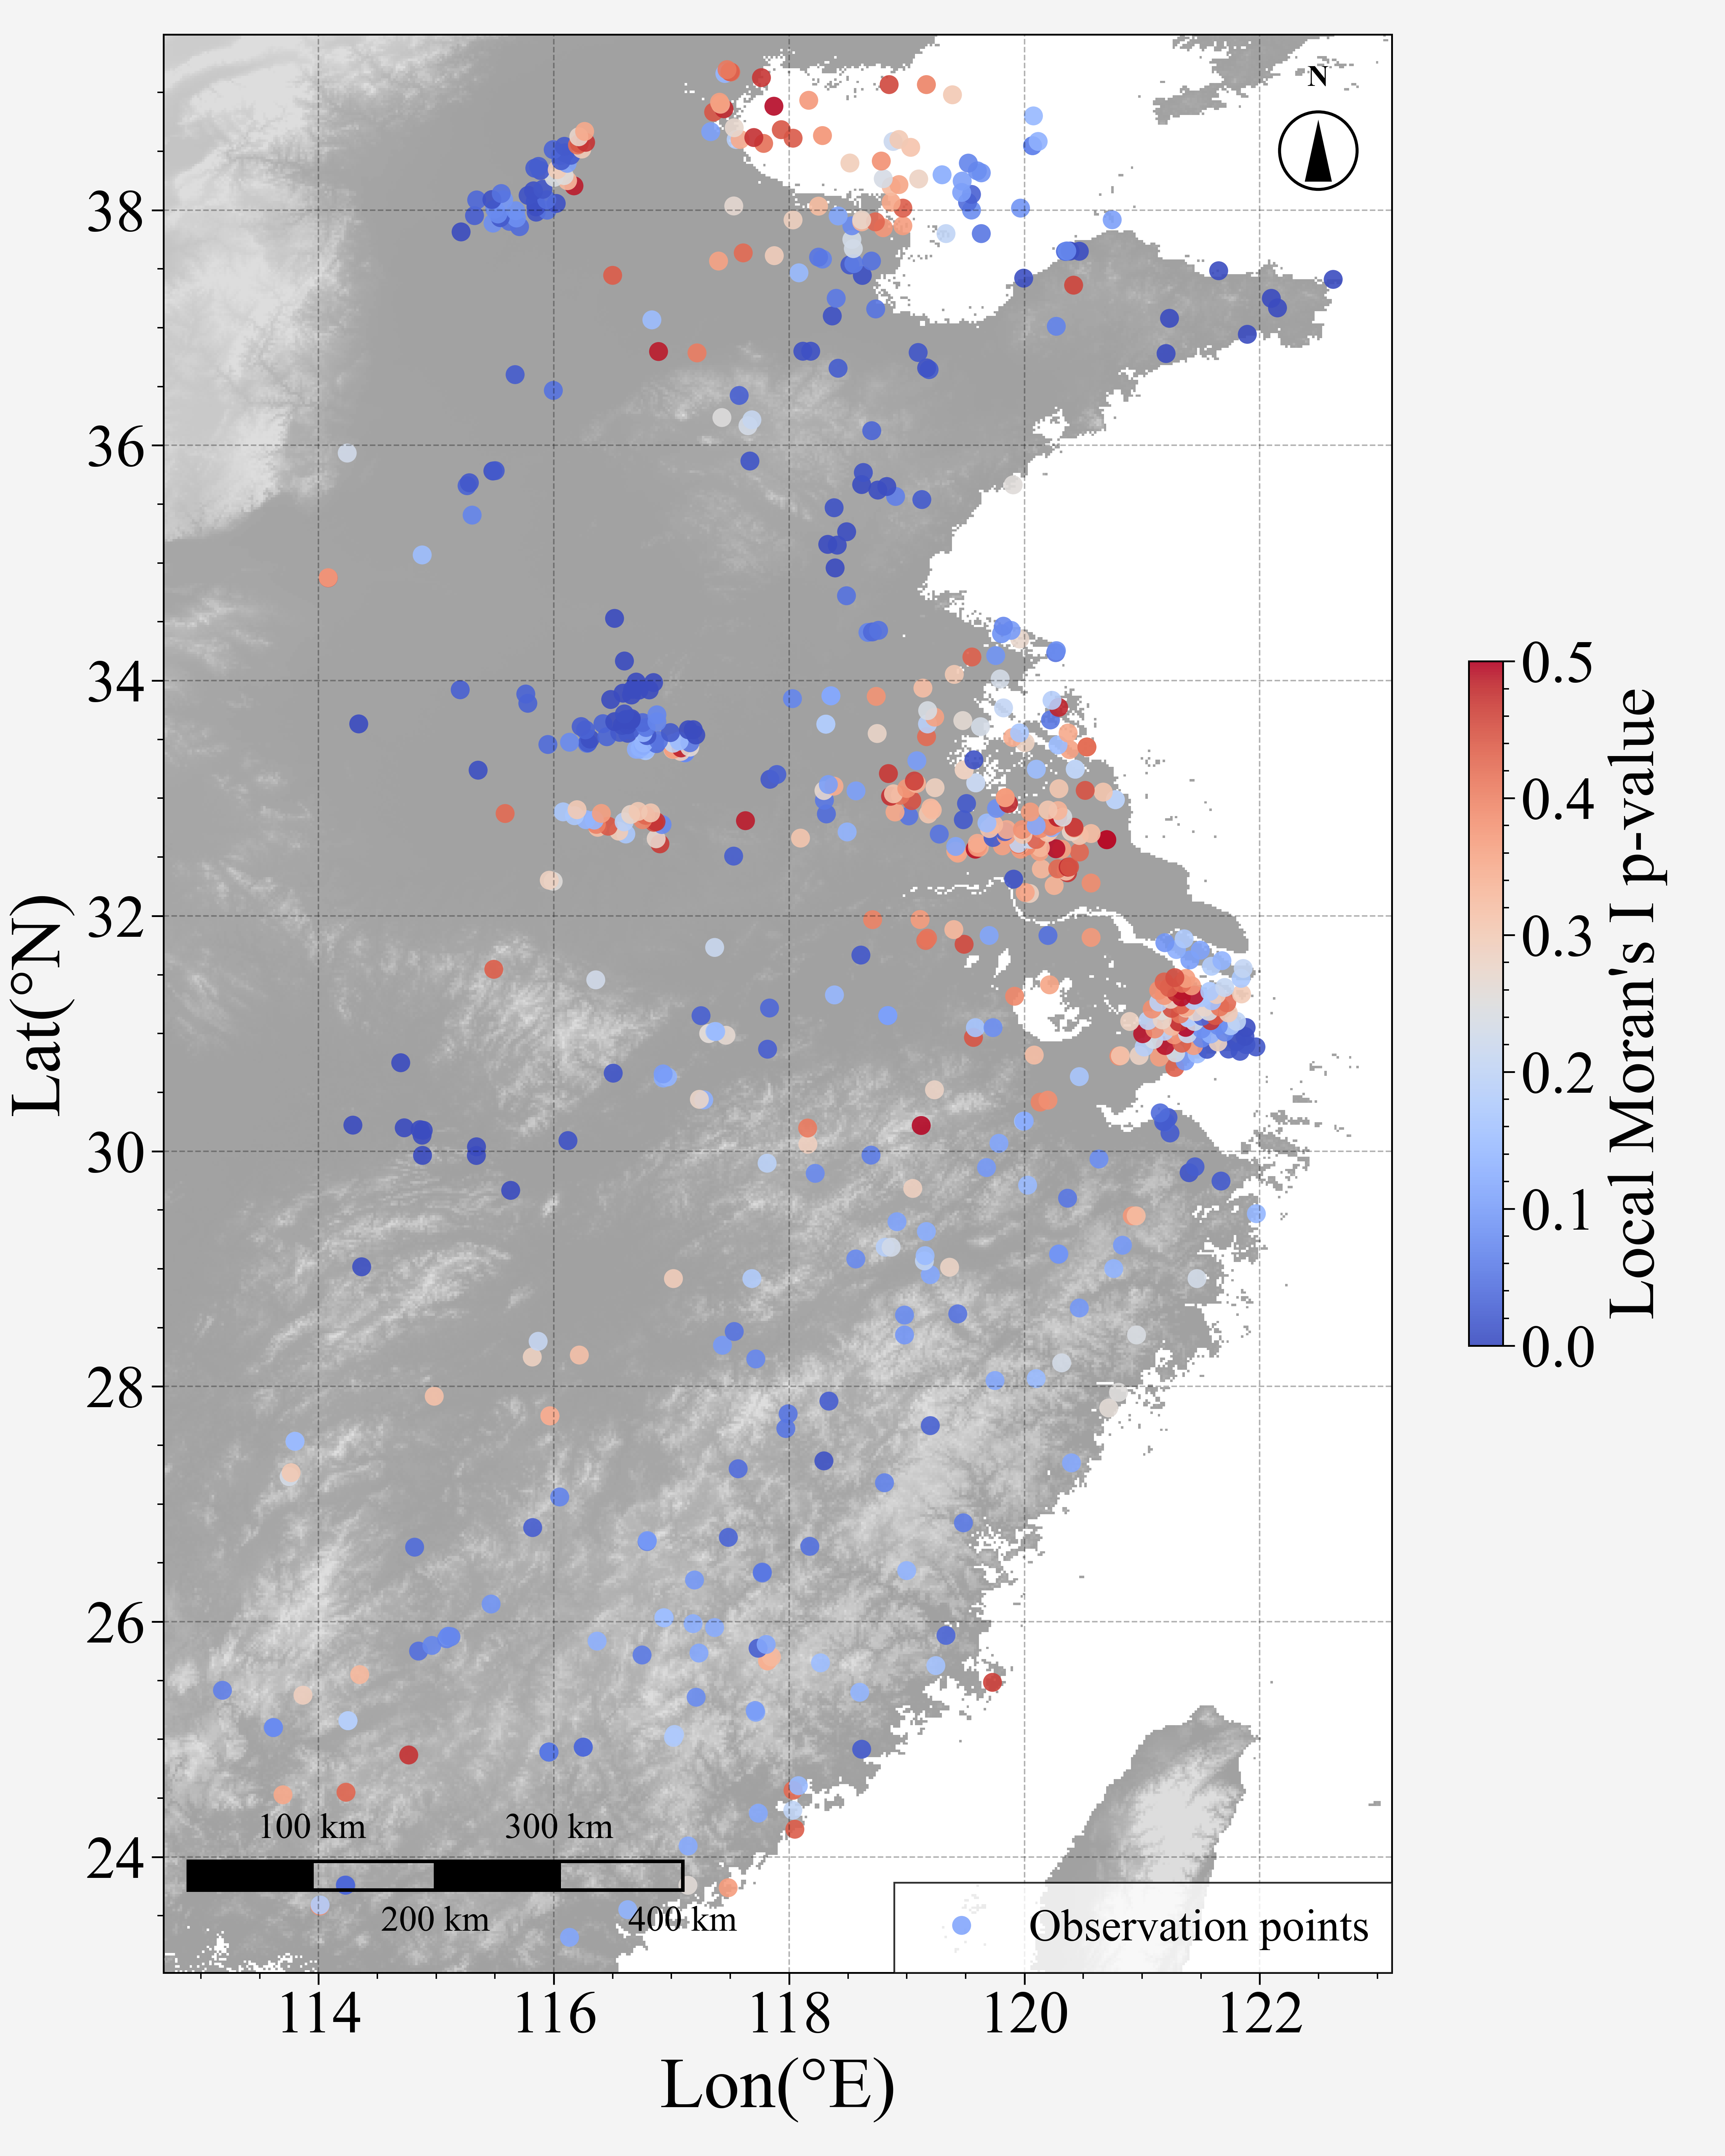


========== Non-stationarity Demonstration Conclusion ==========
The p-values of Local Moran's I show clear spatial variation: some areas have p < 0.05 (significant clustering),
while others have p > 0.05 (random pattern). This non-uniform distribution indicates that the strength of
spatial autocorrelation of SHF varies with location, i.e., significant spatial non-stationarity exists.
Additionally, if residual global autocorrelation is still significant (see previous test), it further confirms
that the current linear model cannot fully capture the non-stationary process, and methods like
Geographically Weighted Regression (GWR) should be considered.


In [8]:
# ==================== Import necessary libraries ====================
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import libpysal as lps
from libpysal.weights import lag_spatial
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin
import warnings
warnings.filterwarnings('ignore')

from esda import Moran
from esda.moran import Moran_Local
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==================== Font settings ====================
plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# ==================== Scale bar and north arrow ====================
def add_scale_bar_and_north_arrow(ax, segment_km=100, num_segments=4):
    """Black-white alternating scale bar and north arrow."""
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    width = xlim[1] - xlim[0]
    height = ylim[1] - ylim[0]
    lat_center = np.mean(ylim)
    km_per_deg_lon = 111.32 * np.cos(np.radians(lat_center))
    dx_per_seg = segment_km / km_per_deg_lon
    x_start = xlim[0] + 0.02 * width
    y_base = ylim[0] + 0.05 * height
    bar_height = 0.015 * height

    for i in range(num_segments):
        x_left = x_start + i * dx_per_seg
        facecolor = 'black' if i % 2 == 0 else 'none'
        rect = plt.Rectangle((x_left, y_base - bar_height / 2), dx_per_seg, bar_height,
                             edgecolor='black', facecolor=facecolor, linewidth=1.2,
                             clip_on=False)
        ax.add_patch(rect)
        cumulative_km = (i + 1) * segment_km
        text_y = y_base + bar_height / 2 + 0.008 * height if i % 2 == 0 else y_base - bar_height / 2 - 0.008 * height
        va = 'bottom' if i % 2 == 0 else 'top'
        ax.text(x_left + dx_per_seg, text_y, f'{cumulative_km} km', ha='center', va=va,
                fontsize=12, color='black', clip_on=False)

    margin = 0.06
    x0 = xlim[1] - margin * width
    y0 = ylim[1] - margin * height
    radius = 0.02 * height
    arrow_length = 0.8 * radius
    circle = mpatches.Circle((x0, y0), radius, facecolor='white', edgecolor='black',
                             linewidth=1.0, zorder=10, clip_on=False)
    ax.add_patch(circle)
    triangle = mpatches.Polygon(
        [(x0, y0 + arrow_length), (x0 - 0.35 * radius, y0 - arrow_length),
         (x0 + 0.35 * radius, y0 - arrow_length)],
        facecolor='black', edgecolor='none', zorder=11, clip_on=False)
    ax.add_patch(triangle)
    ax.text(x0, y0 + radius + 0.01 * height, 'N', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='black', clip_on=False)

# ==================== 1. Read data and preliminary cleaning ====================
df_SHF = pd.read_excel('../output/interpolated_to_SHF.xlsx')
GEO_COLS = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB',
    'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF', 'sedthk-m', 'ro8',
    'vp8', 'vs8', 'DTR'
]
required_cols = ['Lon', 'Lat', 'SHF__mW_m2_'] + GEO_COLS
missing_cols = [col for col in required_cols if col not in df_SHF.columns]
if missing_cols:
    raise KeyError(f"DataFrame missing columns: {missing_cols}")
df_clean = df_SHF[required_cols].dropna()
print(f"Original samples: {len(df_SHF)}, after cleaning: {len(df_clean)}")

gdf = gpd.GeoDataFrame(
    df_clean,
    geometry=[Point(x, y) for x, y in zip(df_clean['Lon'], df_clean['Lat'])],
    crs='EPSG:4326'
)
coords = np.array([(geom.x, geom.y) for geom in gdf.geometry])
k_neighbors = 6
w = lps.weights.KNN(coords, k=k_neighbors)
w.transform = 'R'
print(f"Spatial weights matrix built, average neighbors: {w.mean_neighbors:.2f}")

y = gdf['SHF__mW_m2_'].values
X_raw = gdf[GEO_COLS].values
Wy = lag_spatial(w, y).reshape(-1, 1)

class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.standard_scaler = StandardScaler()
        self.minmax_scaler = MinMaxScaler()

    def fit(self, X, y=None):
        X_std = self.standard_scaler.fit_transform(X)
        self.minmax_scaler.fit(X_std)
        return self

    def transform(self, X):
        X_std = self.standard_scaler.transform(X)
        return self.minmax_scaler.transform(X_std)

scaler_X = StandardThenMinMaxScaler()
X_scaled = scaler_X.fit_transform(X_raw)
scaler_Wy = StandardThenMinMaxScaler()
Wy_scaled = scaler_Wy.fit_transform(Wy)
X_all = np.hstack([X_scaled, Wy_scaled])

Linear_cv = LinearRegression()
Linear_cv.fit(X_all, y)
residuals = y - Linear_cv.predict(X_all)
gdf['residuals'] = residuals
moran_resid = Moran(residuals, w, permutations=999)
print("\n========== Residual Spatial Autocorrelation Test Results ==========")
print(f"Residual Moran's I: {moran_resid.I:.4f}")
print(f"Expected E(I): {moran_resid.EI:.4f}")
if hasattr(moran_resid, 'VI'):
    print(f"Variance Var(I): {moran_resid.VI:.4f}")
elif hasattr(moran_resid, 'V'):
    print(f"Variance Var(I): {moran_resid.V:.4f}")
print(f"z-score: {moran_resid.z_norm:.4f}")
print(f"p-value (normal): {moran_resid.p_norm:.4f}")

local_moran = Moran_Local(y, w, permutations=999)
gdf['local_I'] = local_moran.Is
gdf['local_p'] = local_moran.p_sim
gdf['significant'] = local_moran.p_sim < 0.2
n_sig = int(gdf['significant'].sum())
print(f"Local Moran's I analysis completed. {n_sig} points show significant spatial autocorrelation (p < 0.2).")
print(f"Percentage: {n_sig / len(gdf) * 100:.2f}%")

# ==================== Contour boundary ====================
try:
    from shapely.geometry import Polygon, MultiPolygon, LineString, MultiLineString
    _HAS_GEOPANDAS = True
except ImportError:
    _HAS_GEOPANDAS = False

def plot_boundary(ax, gdf_boundary, color='red', linewidth=1.5):
    for geom in gdf_boundary.geometry:
        if geom.is_empty:
            continue
        if geom.geom_type in ['Polygon', 'MultiPolygon']:
            geom = geom.boundary
        if geom.geom_type == 'LineString':
            x_line, y_line = zip(*geom.coords)
            ax.plot(x_line, y_line, color=color, linewidth=linewidth)
        elif geom.geom_type == 'MultiLineString':
            for line in geom.geoms:
                x_line, y_line = zip(*line.coords)
                ax.plot(x_line, y_line, color=color, linewidth=linewidth)

# ==================== Plot local Moran I p-value spatial distribution ====================
vmin_p, vmax_p = 0.0, 0.5
fig, ax = plt.subplots(figsize=(8, 10))

# ==================== Gray-white terrain basemap ====================
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir

# Use the same local proxy fallback as the upper terrain-basemap cell.
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        _os.environ[_key] = _proxy_url
else:
    print('[GMT] Local proxy not detected; trying direct GMT access')

import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)

    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0
        if np.any(land):
            t = np.clip(v[land] / self.vland, 0.0, 1.0)
            out[land] = self.gray_lo + t * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
_t_lon_mesh = _t_lat_mesh = _t_dem = None
try:
    import pygmt
    _region = [gdf.geometry.x.min() - 1.0, gdf.geometry.x.max() + 1.0,
               gdf.geometry.y.min() - 0.5, gdf.geometry.y.max() + 0.5]
    _relief = pygmt.datasets.load_earth_relief(
        resolution='15s', region=_region, registration=None)
    _step = 5
    _t_lon_mesh, _t_lat_mesh = np.meshgrid(
        _relief.lon.values[::_step], _relief.lat.values[::_step])
    _t_dem = _relief.values[::_step, ::_step].astype(float)
    print(f"Gray-white terrain loaded for Local Moran map: {_t_dem.shape}")
except Exception as _e:
    print(f"Warning: terrain loading failed: {_e}, skip terrain basemap")

# Clip the terrain to the same visible observation-point extent as the map.
if _t_dem is not None:
    _inside_extent = (
        (_t_lon_mesh >= gdf.geometry.x.min() - 0.5) &
        (_t_lon_mesh <= gdf.geometry.x.max() + 0.5) &
        (_t_lat_mesh >= gdf.geometry.y.min() - 0.3) &
        (_t_lat_mesh <= gdf.geometry.y.max() + 0.3)
    )
    _dem_visible = np.ma.masked_where(~_inside_extent, _t_dem)
    ax.pcolormesh(_t_lon_mesh, _t_lat_mesh, _dem_visible,
                  cmap='Greys_r', norm=_gray_norm,
                  shading='auto', alpha=0.9, zorder=0)

# ==================== Local Moran points and annotations ====================
sc = ax.scatter(gdf.geometry.x, gdf.geometry.y, c=gdf['local_p'],
                cmap='coolwarm', edgecolors='none', s=40, alpha=0.9,
                vmin=vmin_p, vmax=vmax_p, label='Observation points')
cbar = plt.colorbar(sc, ax=ax, shrink=0.35)
cbar.ax.tick_params(labelsize=20)
cbar.set_label("Local Moran's I p-value", fontsize=22)
ax.set_xlabel('Lon(°E)', fontsize=24)
ax.set_ylabel('Lat(°N)', fontsize=24)
ax.tick_params(axis='both', labelsize=20)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

shapefile_path = '../data/eastChinaLine.shp'
if _HAS_GEOPANDAS:
    try:
        gdf_boundary = gpd.read_file(shapefile_path)
        if gdf_boundary.crs is not None and gdf_boundary.crs != 'EPSG:4326':
            gdf_boundary = gdf_boundary.to_crs('EPSG:4326')
        plot_boundary(ax, gdf_boundary, color='none', linewidth=1.2)
        print("Successfully overlaid contour lines")
    except Exception as e:
        print(f"Cannot load or plot contour lines: {e}")

ax.set_xlim(gdf.geometry.x.min() - 0.5, gdf.geometry.x.max() + 0.5)
ax.set_ylim(gdf.geometry.y.min() - 0.3, gdf.geometry.y.max() + 0.3)
add_scale_bar_and_north_arrow(ax, segment_km=100, num_segments=4)
ax.legend(loc='lower right', fontsize=15, frameon=True, facecolor='white', edgecolor='black')
plt.tight_layout()
plt.savefig('../output/local_moran_pvalues_with_boundary.png', dpi=1000)
plt.show()

print("\n========== Non-stationarity Demonstration Conclusion ==========")
print("The p-values of Local Moran's I show clear spatial variation: some areas have p < 0.05 (significant clustering),")
print("while others have p > 0.05 (random pattern). This non-uniform distribution indicates that the strength of")
print("spatial autocorrelation of SHF varies with location, i.e., significant spatial non-stationarity exists.")
print("Additionally, if residual global autocorrelation is still significant (see previous test), it further confirms")
print("that the current linear model cannot fully capture the non-stationary process, and methods like")
print("Geographically Weighted Regression (GWR) should be considered.")